In [9]:
import csv
import errno
import itertools
import os
import pickle
import sys
import traceback
import json

import matplotlib.lines as lines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator, FormatStrFormatter
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
import glob
import re

In [10]:
def compute_per_bin_metrics(bins_per_rep, n_repeats=5, M=10):
    # Compute instance fraction for each bin: used only for reliability diagrams (not for CW-ECE)
    instances_for_bin = []
    for j in range(n_repeats):
        for i in range(M):
            instances_for_bin.append(len(bins_per_rep[j][i]))
    instances_for_bin = np.reshape(np.asarray(instances_for_bin), (n_repeats, M))
    mean_fraction = np.round(instances_for_bin.mean(axis=0) / instances_for_bin.mean(axis=0).sum() * 100, 2)

    # Compute accuracy and confidence for each bin
    accuracy_per_rep = []
    confidence_per_rep = []
    for bins in bins_per_rep:
        accuracy_per_rep.append([])
        confidence_per_rep.append([])
        for ibin in bins:
            if len(ibin) > 0:
                accuracy_per_bin = []
                confidence_per_bin = []
                for s in ibin:
                    accuracy_per_bin.append(1 if s[0] == s[1] else 0)
                    confidence_per_bin.append(s[2])

                accuracy_per_rep[-1].append(np.sum(accuracy_per_bin) / len(ibin))
                confidence_per_rep[-1].append(np.sum(confidence_per_bin) / len(ibin))

            else:
                accuracy_per_rep[-1].append(0)
                confidence_per_rep[-1].append(0)

    return mean_fraction, accuracy_per_rep, confidence_per_rep

In [11]:
def compute_per_bin_per_class_metrics(bins_per_rep_per_class):
    # Compute per-class accuracy and confidence for each bin
    # Fold
    accuracy_per_rep_per_class = []
    confidence_per_rep_per_class = []
    for bins in bins_per_rep_per_class:
        # Bin
        accuracy_per_rep_per_class.append([])
        confidence_per_rep_per_class.append([])
        for i, class_bin in enumerate(bins):
            # Class
            accuracy_per_rep_per_class[-1].append([])
            confidence_per_rep_per_class[-1].append([])
            for j, ijbin in enumerate(class_bin):
                if len(ijbin) > 0:
                    accuracy_per_bin_per_class = []
                    confidence_per_bin_per_class = []
                    # Sample
                    for s in ijbin:
                        accuracy_per_bin_per_class.append(1 if s[0] == j else 0)
                        confidence_per_bin_per_class.append(s[3])

                    # Aij: percentage of jth-class samples (with respect to actual) in the ith bin
                    accuracy_per_rep_per_class[-1][-1].append(np.sum(accuracy_per_bin_per_class) / len(ijbin))
                    # Cij: average confidence of jth class (s[3] is the jth probability)
                    confidence_per_rep_per_class[-1][-1].append(np.sum(confidence_per_bin_per_class) / len(ijbin))

                else:
                    accuracy_per_rep_per_class[-1][-1].append(0)
                    confidence_per_rep_per_class[-1][-1].append(0)

    return accuracy_per_rep_per_class, confidence_per_rep_per_class

In [12]:
def compute_ece_mce(samples, bins_per_rep, accuracy_per_rep, confidence_per_rep):
    # Compute ECE and MCE for each bin
    expected_confidence_error_per_rep = []
    maximum_calibration_error_per_rep = []
    signed_calibration_error_per_rep = []
    for i, (bins, accuracy, confidence) in enumerate(zip(bins_per_rep, accuracy_per_rep, confidence_per_rep)):
        sample_num = len(samples[i])
        # Mean ECE
        expected_confidence_error_per_rep.append(np.sum(
            [len(ibin) * np.abs(bin_acc - bin_conf) for ibin, bin_acc, bin_conf in
             zip(bins, accuracy, confidence)]) / sample_num)
        # Signed ECE
        signed_calibration_error_per_rep.append(np.sum(
            [len(ibin) * (bin_acc - bin_conf) for ibin, bin_acc, bin_conf in
             zip(bins, accuracy, confidence)]) / sample_num)
        # Mean MCE
        maximum_calibration_error_per_rep.append(np.max(
            [np.abs(bin_acc - bin_conf) for bin_acc, bin_conf in zip(accuracy, confidence)]))

    return expected_confidence_error_per_rep, maximum_calibration_error_per_rep, signed_calibration_error_per_rep


def compute_cw_ece(samples, bins_per_rep_per_class, accuracy_per_rep_per_class, confidence_per_rep_per_class,
                   num_classes):
    # Compute CW-ECE for each bin
    class_wise_expected_confidence_error_per_rep = []
    for i, (bins_per_class, accuracy_per_class, confidence_per_class) in enumerate(
            zip(bins_per_rep_per_class, accuracy_per_rep_per_class, confidence_per_rep_per_class)):
        sample_num = len(samples[i])

        class_wise_expected_confidence_error_per_bin_per_rep = []
        for bin_samples, bin_accuracies, bin_confidences in zip(
                bins_per_class, accuracy_per_class, confidence_per_class):
            class_wise_expected_confidence_error_per_bin_per_rep.append(np.sum(
                [len(ijbin) * np.abs(accuracy - confidence) for ijbin, accuracy, confidence in
                 zip(bin_samples, bin_accuracies, bin_confidences)]))

        class_wise_expected_confidence_error_per_rep.append(
            np.sum(class_wise_expected_confidence_error_per_bin_per_rep) / (sample_num * num_classes))

    return class_wise_expected_confidence_error_per_rep

In [13]:
def confidencePlot(M, mean_binlen, average_accuracy, average_confidence, fig,
                   color=None, savefig=None, formatfig='pdf'):
    plt.rc('axes', axisbelow=True)
    plt.rc('font', size=18)
    plt.margins(x=0, y=0)
    plt.bar(np.arange(M) / M, mean_binlen / np.sum(mean_binlen), align='edge', width=1 / M, color=color, edgecolor='k')
    avg_acc = plt.plot([average_accuracy] * 2, [0, 1], color='black', ls='-', lw=3, label='Accuracy')
    avg_conf = plt.plot([average_confidence] * 2, [0, 1], color='orange', ls='--', lw=3, label='Average Confidence')
    plt.legend(loc='best', handlelength=2.65, fontsize=16)
    plt.grid(ls='--')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.ylabel('Accuracy')
    plt.xlabel('Predicted Class Probability')

    ax = fig.axes[0]

    ax.xaxis.set_minor_locator(MultipleLocator(0.1))
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))

    ax.tick_params(axis='x', which='minor', top=False, direction='out')
    ax.tick_params(axis='x', which='major', top=False, direction='out', labelsize=16)
    ax.tick_params(axis='y', which='major', right=False, direction='out', labelsize=16)
    ax.tick_params(axis='y', which='minor', right=False, direction='out')

    ax.xaxis.grid(False)
    ax.yaxis.grid(True)

    majorFormatter = FormatStrFormatter('%g')
    ax.xaxis.set_major_formatter(majorFormatter)
    ax.yaxis.set_major_formatter(majorFormatter)

    if savefig:
        plt.tight_layout()
        plt.savefig(savefig, format=formatfig, bbox_inches='tight', pad_inches=0.05)
    plt.show()

In [14]:
def reliabilityPlot(M, mean_accuracy, mean_ece, num_classes, mean_fraction, fig,
                    color=None, over_color=None, under_color=None,savefig=None, formatfig='pdf'):
    if not color:
        color = 'C0'
    if not over_color:
        color = 'crimson'

    bigsize = 20
    smallsize = bigsize - 2
    verysmallsize = bigsize - 6

    plt.rc('axes', axisbelow=True)
    plt.rc('font', size=bigsize)
    plt.margins(x=0, y=0)
    lower_gap = (np.arange(M) / M + 1 / (2 * M)) * 100
    upper_gap = np.zeros(len(lower_gap))
    lower_acc = np.array(mean_accuracy)
    upper_acc = np.array(mean_accuracy)
    for i, (b, a) in enumerate(zip(lower_gap, lower_acc)):
        if a > b:
            lower_gap[i] = 0
            upper_gap[i] = a
            lower_acc[i] = b
    bar_x = (np.arange(M) / M) * 100
    bar = plt.bar(bar_x, lower_gap, align='edge', width=100 / M, color=over_color, edgecolor='none', alpha=.5)
    plt.bar(bar_x, lower_gap, align='edge', width=100 / M, color='none', edgecolor='k')
    plt.bar(bar_x, upper_gap, align='edge', width=100 / M, color=over_color, edgecolor='none', alpha=.5)
    plt.bar(bar_x, upper_gap, align='edge', width=100 / M, color=under_color, edgecolor='none', alpha=.5)
    plt.bar(bar_x, upper_gap, align='edge', width=100 / M, color='none', edgecolor='k', hatch="\\\\")
    plt.bar(bar_x, lower_acc, align='edge', width=100 / M, color=color, edgecolor='none')
    plt.bar(bar_x, upper_acc, align='edge', width=100 / M, color='none', edgecolor='k')
    plt.plot([0, 100], [0, 100], color='gray', ls='--', lw=3.0)
    oneonl = (1 / num_classes) * 100
    plt.vlines(x=oneonl, ymin=0, ymax=100, color='#00204F', linestyles='dashed', lw=3.0, label=None)
    for i, rect in enumerate(bar):
        plt.text(rect.get_x() + rect.get_width() / 2.0, -0.25, str(mean_fraction[i]),
                 ha='center', va='bottom', fontsize=verysmallsize, color='k', weight='bold')

    positive_gap = (mpatches.Patch(facecolor=over_color, alpha=.5), mpatches.Patch(facecolor='none', edgecolor='k'))
    negative_gap = (mpatches.Patch(facecolor=under_color, alpha=.5), 
                    mpatches.Patch(facecolor='none', hatch='\\\\', edgecolor='k'))
    out = mpatches.Patch(facecolor=color, alpha=1, edgecolor='k')
    ideal = lines.Line2D([0], [0], color='gray', ls='--', lw=3, label='Ideal')
    plt.legend([ideal, out, positive_gap, negative_gap], ['Ideal', 'Actual', 'Over', 'Under'],
               loc='center', handlelength=1.50, handletextpad=0.75, columnspacing=1.25, fontsize=bigsize, numpoints=1,
               ncol=4, bbox_to_anchor=(0.5, 1.1), frameon=False)

    plt.grid(ls='--')
    plt.xlim(0, 100)
    plt.ylim(0, 100)
    plt.ylabel('Accuracy [%]', fontsize=bigsize)
    plt.xlabel('Confidence [%]', fontsize=bigsize)

    ax = fig.axes[0]

    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(5))

    ax.tick_params(axis='x', which='minor', top=False, direction='out')
    ax.tick_params(axis='x', which='major', top=False, direction='out', labelsize=smallsize)
    ax.tick_params(axis='y', which='major', right=False, direction='out', labelsize=smallsize)
    ax.tick_params(axis='y', which='minor', right=False, direction='out')

    ax.xaxis.grid(False)
    ax.yaxis.grid(True)

    majorFormatter = FormatStrFormatter('%g')
    ax.xaxis.set_major_formatter(majorFormatter)
    ax.yaxis.set_major_formatter(majorFormatter)

    if savefig:
        plt.tight_layout()
        plt.savefig(savefig, format=formatfig, bbox_inches='tight', pad_inches=0)

In [15]:
def reliabilityPlotLastBin(M, proba_last_bin, mean_accuracy, mean_fraction, fig,
                           color=None, gapcolor=None, savefig=None, formatfig='pdf'):
    if not color:
        color = 'C0'
    if not gapcolor:
        color = 'crimson'

    bigsize = 20
    smallsize = bigsize - 2
    verysmallsize = bigsize - 6

    plt.rc('axes', axisbelow=True)
    plt.rc('font', size=bigsize)
    plt.margins(x=0, y=0)
    lower_gap = (proba_last_bin + (np.arange(M) / M + 1 / (2 * M)) / M) * 100
    upper_gap = np.zeros(len(lower_gap))
    lower_acc = np.array(mean_accuracy)
    upper_acc = np.array(mean_accuracy)

    for i, (b, a) in enumerate(zip(lower_gap, lower_acc)):
        if a > b:
            lower_gap[i] = 0
            upper_gap[i] = a
            lower_acc[i] = b
    bar = plt.bar(np.linspace(proba_last_bin, proba_last_bin + proba_last_bin / 10, num=10) * 100, lower_gap,
                  align='edge', width=100 / (M * M), color=gapcolor, edgecolor='none', alpha=.5)
    plt.bar(np.linspace(proba_last_bin, proba_last_bin + proba_last_bin / 10, num=10) * 100, lower_gap,
            align='edge', width=100 / (M * M), color='none', edgecolor='k')
    plt.bar(np.linspace(proba_last_bin, proba_last_bin + proba_last_bin / 10, num=10) * 100, upper_gap,
            align='edge', width=100 / (M * M), color=gapcolor, edgecolor='none', alpha=.5)
    plt.bar(np.linspace(proba_last_bin, proba_last_bin + proba_last_bin / 10, num=10) * 100, upper_gap,
            align='edge', width=100 / (M * M), color=color, edgecolor='none', alpha=.5)
    plt.bar(np.linspace(proba_last_bin, proba_last_bin + proba_last_bin / 10, num=10) * 100, upper_gap,
            align='edge', width=100 / (M * M), color='none', edgecolor='k', hatch="\\\\")
    plt.bar(np.linspace(proba_last_bin, proba_last_bin + proba_last_bin / 10, num=10) * 100, lower_acc,
            align='edge', width=100 / (M * M), color=color, edgecolor='none')
    plt.bar(np.linspace(proba_last_bin, proba_last_bin + proba_last_bin / 10, num=10) * 100, upper_acc,
            align='edge', width=100 / (M * M), color='none', edgecolor='k')
    plt.plot([proba_last_bin * 100, 100], [proba_last_bin * 100, 100], color='gray', ls='--', lw=3.0)
    for i, rect in enumerate(bar):
        plt.text(rect.get_x() + rect.get_width() / 2.0, 50, str(mean_fraction[i]),
                 ha='center', va='bottom', fontsize=verysmallsize, color='white', weight='bold')

    positive_gap = (mpatches.Patch(facecolor=gapcolor, alpha=.5), mpatches.Patch(facecolor='none', edgecolor='k'))
    negative_gap = (mpatches.Patch(facecolor=gapcolor, alpha=.5), mpatches.Patch(facecolor=color, alpha=.5),
                    mpatches.Patch(facecolor='none', hatch='\\\\', edgecolor='k'))
    out = mpatches.Patch(facecolor=color, alpha=1, edgecolor='k')
    ideal = lines.Line2D([0], [0], color='gray', ls='--', lw=3, label='Ideal')
    plt.legend([ideal, out, positive_gap, negative_gap], ['Ideal', 'Actual', 'Over', 'Under'],
               loc='center', handlelength=1.50, handletextpad=0.75, columnspacing=1.25, fontsize=bigsize, numpoints=1,
               ncol=4, bbox_to_anchor=(0.5, 1.1), frameon=False)

    plt.grid(ls='--')
    plt.xlim(90, 100)
    plt.ylim(50, 100)
    plt.ylabel('Accuracy [%]', fontsize=bigsize)
    plt.xlabel('Confidence [%] (detail)', fontsize=bigsize)

    ax = fig.axes[0]

    ax.xaxis.set_minor_locator(MultipleLocator(1))
    ax.yaxis.set_minor_locator(MultipleLocator(2))

    ax.tick_params(axis='x', which='minor', top=False, direction='out')
    ax.tick_params(axis='x', which='major', top=False, direction='out', labelsize=smallsize)
    ax.tick_params(axis='y', which='major', right=False, direction='out', labelsize=smallsize)
    ax.tick_params(axis='y', which='minor', right=False, direction='out')

    ax.xaxis.grid(False)
    ax.yaxis.grid(True)

    majorFormatter = FormatStrFormatter('%g')
    ax.xaxis.set_major_formatter(majorFormatter)
    ax.yaxis.set_major_formatter(majorFormatter)

    if savefig:
        plt.tight_layout()
        plt.savefig(savefig, format=formatfig, bbox_inches='tight', pad_inches=0)

In [41]:
classes_config = {
    'cic-iomt': 17,
    'edge-iiot': 14,
    'iot-nidd': 10,
}

def rel_diagram(path, title, protocol, outdir, n_repeats=5, ds_name='edge-iiot', dirs=['fold_1', 'fold_2', 'fold_3', 'fold_4', 'fold_5']):

    M = 10
    proba_last_bin = 0.9

    classes=set([])
    for index, rep_dir in enumerate(dirs):
        file_name = f"{model_dir}/{rep_dir}/soft_output.dat"

        with open(file_name, 'r') as fin:
            csvreader = csv.reader(fin, delimiter='\t')
            next(csvreader)
            for elem, line in enumerate(csvreader):
                    actual = int(line[0])
                    classes.add(actual)
    num_classes = len(classes)


    samples = []
    samples_last_bin = []
    for index, rep_dir in enumerate(dirs):

        files=glob.glob(os.path.join(path,rep_dir)+'/**/soft_output.dat',recursive=True)
        assert len(files)>0, 'Soft values not found in %s'%os.path.join(path,rep_dir)

        files = [f for f in files if 'training_soft_values' not in f]
        if len(files)==1:
            file_name=files[0]
        elif len(files)>1:
            file_name=[f for f in files if os.path.basename(f).startswith('multimodal_')][0]

        with open(file_name, 'r') as fin:
            csvreader = csv.reader(fin, delimiter='\t')
            next(csvreader)
            samples_per_rep = []
            samples_per_rep_last_bin = []
            for elem, line in enumerate(csvreader):
                    num_classes = classes_config[ds_name]
                    actual = range(num_classes).index(int(line[0]))
                    soft_values = [float(x) for x in line[1:][0].split(',')]
                    predicted = np.argmax(soft_values)
                    max_proba = round(float(np.max(soft_values)), 4)
                    samples_per_rep.append([actual, predicted, max_proba, soft_values])
                    if max_proba >= proba_last_bin:
                        samples_per_rep_last_bin.append([actual, predicted, max_proba])
        samples.append(samples_per_rep)
        samples_last_bin.append(samples_per_rep_last_bin)

    bins_per_rep = []
    bins_per_rep_per_class = []
    for samples_per_rep in samples:
        bins_per_rep.append([])
        bins_per_rep_per_class.append([])
        for i in range(1, M + 1):
            bins_per_rep[-1].append([])
            bins_per_rep_per_class[-1].append([[] for _ in range(num_classes)])
            for sample in samples_per_rep:
                if (i - 1) / M < sample[2] <= i / M:
                    bins_per_rep[-1][-1].append([sample[0], sample[1], sample[2]])
                for jclass in range(num_classes):
                    if ((i - 1) / M < sample[3][jclass] <= i / M) or (i == 1 and sample[3][jclass] == 0):
                        bins_per_rep_per_class[-1][-1][jclass].append(
                            [sample[0], sample[1], sample[2], sample[3][jclass]])

    bins_per_rep_last_bin = []
    for samples_per_rep_last_bin in samples_last_bin:
        bins_per_rep_last_bin.append([])
        for i in range(1, M + 1):
            bins_per_rep_last_bin[-1].append([])
            for sample in samples_per_rep_last_bin:
                if proba_last_bin + ((i - 1) / M) / M < sample[2] <= proba_last_bin + (i / M) / M:
                    bins_per_rep_last_bin[-1][-1].append(sample)

    mean_fraction, accuracy_per_rep, confidence_per_rep = compute_per_bin_metrics(bins_per_rep, n_repeats, M)


    expected_confidence_error_per_rep, \
    maximum_calibration_error_per_rep, signed_calibration_error_per_rep = \
        compute_ece_mce(samples, bins_per_rep, accuracy_per_rep, confidence_per_rep)

    mean_binlen = np.mean(np.array([[len(ibin) for ibin in bins] for bins in bins_per_rep]), axis=0)
    std_binlen = np.std(np.array([[len(ibin) for ibin in bins] for bins in bins_per_rep]), axis=0)

    mean_accuracy = np.mean(np.array(accuracy_per_rep), axis=0) * 100
    std_accuracy = np.std(np.array(accuracy_per_rep), axis=0) * 100

    mean_confidence = np.mean(np.array(confidence_per_rep), axis=0) * 100
    std_confidence = np.std(np.array(confidence_per_rep), axis=0) * 100

    mean_ece = np.mean(np.array(expected_confidence_error_per_rep), axis=0)
    mean_ece = np.round(mean_ece * 100, 4)
    std_ece = np.std(np.array(expected_confidence_error_per_rep), axis=0)
    std_ece = np.round(std_ece * 100, 4)

    mean_mce = np.mean(np.array(maximum_calibration_error_per_rep), axis=0)
    mean_mce = np.round(mean_mce * 100, 4)
    std_mce = np.std(np.array(maximum_calibration_error_per_rep), axis=0)
    std_mce = np.round(std_mce * 100, 4)

    mean_cw_ece = np.nan
    std_cw_ece = np.nan
    average_accuracy = np.average(mean_accuracy, weights=mean_binlen)
    average_confidence = np.average(mean_confidence, weights=mean_binlen)

    mean_fraction_last_bin, accuracy_per_rep_last_bin, confidence_per_rep_last_bin = \
        compute_per_bin_metrics(bins_per_rep_last_bin, n_repeats=n_repeats)

    mean_accuracy_last_bin = np.mean(np.array(accuracy_per_rep_last_bin), axis=0) * 100
    std_accuracy_last_bin = np.std(np.array(accuracy_per_rep_last_bin), axis=0) * 100

    if 'focal' in title:
        color = '#191970'
        gapcolor = '#4169E1'
    elif 'ls' in title:
        color = '#228B22'
        gapcolor = '#32CD32'
    elif 'mimetic' in title:
        color = '#c70039'
        gapcolor = '#ff847c'
    else:
        color = '#f0a500'
        gapcolor = '#fbd46d'

    color = '#2b50aa'
    gapcolor= '#ff858d'
    
    # print('>>>>>Saving in: %s'%outdir)
    fig = plt.figure(num=2, figsize=(9.4, 4.7))
    savefig = '%s/%s_rel_diag.pdf' % (outdir, title)
    reliabilityPlot(M, mean_accuracy, mean_ece, num_classes, mean_fraction, fig,
                    color='#E6E8E6', over_color='#e86a92', under_color='#f7e733' , savefig=savefig, formatfig='pdf')

    fig = plt.figure(num=3, figsize=(9.4, 4.7))
    savefig = '%s/%s_rel_diag_last_bin.pdf' % (outdir, title)
    reliabilityPlotLastBin(M, proba_last_bin, mean_accuracy_last_bin, mean_fraction_last_bin, fig,
                            color=color, gapcolor=gapcolor, savefig=savefig, formatfig='pdf')

    # Over- or under-confident?
    mean_signed_ece = np.mean(
        np.array(signed_calibration_error_per_rep),
        axis=0
    ) * 100
    is_overconfident = mean_signed_ece < 0

    return mean_ece, std_ece, mean_mce, std_mce, mean_cw_ece, std_cw_ece, is_overconfident

In [42]:
base_folder = f"/home/{os.environ['USER']}/qml-nids/Results"
outdir = f"{base_folder}/plots/oc5"

fake_backends = ["fake_lagos", "fake_nairobi", "fake_london", "fake_yorktown", "fake_fractbackend"]
n_shotss = [8, 64, 1024]

dataset_name = 'edge-iiot'
model_name = 'hybrid_ampe_probs'

Processing edge-iiot results...
Processing iot-nidd results...
Processing cic-iomt results...


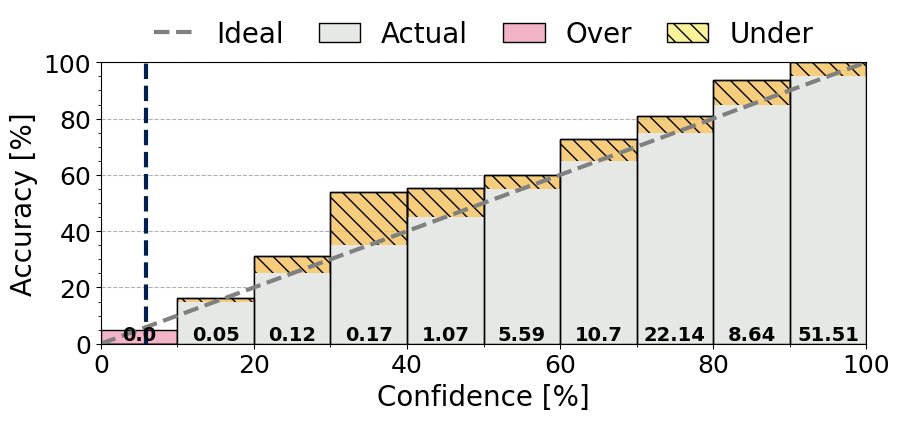

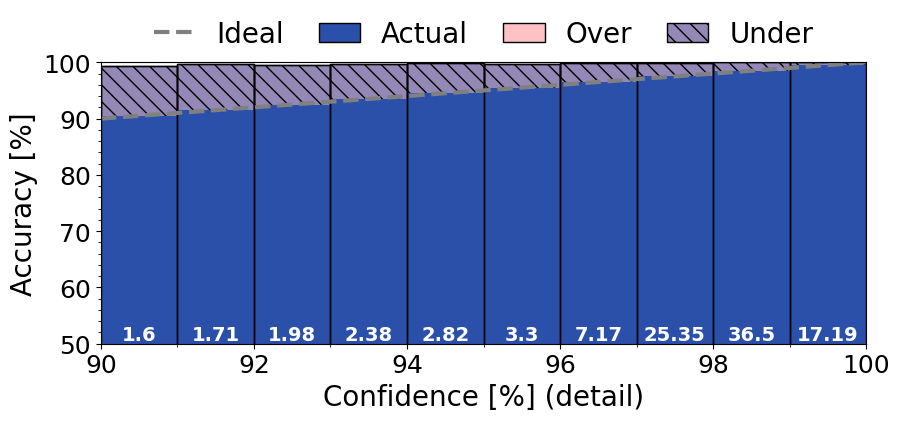

In [43]:
for dataset_name in ['edge-iiot', 'iot-nidd', 'cic-iomt']:
    print(f'Processing {dataset_name} results...')
    for fb in fake_backends:
        for n_shots in n_shotss:
            plt.close("all")
            model_dir = f'{base_folder}/models_outputs/{dataset_name}/noisy_models/{fb}/{n_shots}shots/{model_name}'

            title = f"rel_{dataset_name}_{model_name}_{fb}_{n_shots}shots"

            os.makedirs(outdir, exist_ok=True)

            ece_list = ['ECE']
            mce_list = ['MCE']
            cw_ece_list = ['CW-ECE']

            protocol_numbers = ['all']
            protocols = ['all']

            for i, protocol_number in enumerate(protocol_numbers):
                mean_ece, std_ece, mean_mce, std_mce, mean_cw_ece, std_cw_ece, is_overconfident = \
                    rel_diagram(model_dir, title, protocol_number, outdir, n_repeats=5, ds_name=dataset_name)
                ece_list.extend([mean_ece, std_ece])
                mce_list.extend([mean_mce, std_mce])
                cw_ece_list.extend([mean_cw_ece, std_cw_ece])

            csvheader = ['Metric']
            for elem in itertools.product(*[protocols, ['mean', 'std']]):
                csvheader.append('_'.join(elem))

            with open(outdir + '/' + title + '.csv', 'w') as f:
                csvwriter = csv.writer(f)
                csvwriter.writerow(csvheader)
                csvwriter.writerow(ece_list)
                csvwriter.writerow(mce_list)
                csvwriter.writerow(cw_ece_list)

In [ ]:
classical_ds = {}
noiseless_ds = {}

for model_name in ["hybrid", "hybrid_ampe_probs"]:

    for dataset_name in ["cic-iomt", "edge-iiot", "iot-nidd"]:
        plt.close("all")
        model_dir = f'{base_folder}/models_outputs/{dataset_name}/trained_models/100perc/{model_name}'
        result_dir = model_dir
        title = f"rel_{dataset_name}_{model_name}"

        os.makedirs(outdir, exist_ok=True)

        ece_list = ['ECE']
        mce_list = ['MCE']
        cw_ece_list = ['CW-ECE']

        protocol_numbers = ['all']
        protocols = ['all']
        for i, protocol_number in enumerate(protocol_numbers):
            mean_ece, std_ece, mean_mce, std_mce, mean_cw_ece, std_cw_ece, is_overconfident = \
                rel_diagram(result_dir, title, protocol_number, outdir, n_repeats=5, ds_name=dataset_name)
            ece_list.extend([mean_ece, std_ece])
            mce_list.extend([mean_mce, std_mce])
            cw_ece_list.extend([mean_cw_ece, std_cw_ece])

        csvheader = ['Metric']
        for elem in itertools.product(*[protocols, ['mean', 'std']]):
            csvheader.append('_'.join(elem))

        with open(outdir + '/' + title + '.csv', 'w') as f:
            csvwriter = csv.writer(f)
            csvwriter.writerow(csvheader)
            csvwriter.writerow(ece_list)
            csvwriter.writerow(mce_list)
            csvwriter.writerow(cw_ece_list)

        if model_name == "hybrid":
            classical_ds[dataset_name] = mean_ece
            classical_ds[f"{dataset_name}_std"] = std_ece
            classical_ds[f"{dataset_name}_overconfident"] = is_overconfident

        elif model_name == "hybrid_ampe_probs":
            noiseless_ds[dataset_name] = mean_ece
            noiseless_ds[f"{dataset_name}_std"] = std_ece
            classical_ds[f"{dataset_name}_overconfident"] = is_overconfident